In [ ]:
import sys
import os
# Resolve repo root (contains setup.py) and ensure it's on sys.path so that
# 'src.flowsync' imports work regardless of Jupyter's working directory.
_cwd = os.getcwd()
_root = _cwd
while _root != os.path.dirname(_root):
    if os.path.exists(os.path.join(_root, 'setup.py')):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
os.chdir(_root)  # also set CWD so relative paths in later cells work
import sys
import os
# sys.path.append("../../../../helper_funcs") # Removed in favor of package import
from src.flowsync.models.architectures import *
from src.flowsync.utils.plotting import *
from src.flowsync.utils.data_processing import *
from tensorflow.keras.callbacks import Callback
from tensorflow.keras import backend as K  # Import the Keras backend

### (Optional) Force TensorFlow to use the CPU only

In [2]:
#tf.config.set_visible_devices([], 'GPU')

### (Optional) Disable mixed-precision if using GPUs to avoid mismatch in `model.keras` saved model - not a big deal

In [3]:
# from tensorflow.keras.mixed_precision import Policy, set_global_policy

# # Set the precision policy to float32
# policy = Policy('float32')
# set_global_policy(policy)

# # Set deterministic behavior for GPUs and CPUs
# seed = 42
# tf.random.set_seed(seed)
# np.random.seed(seed)
# random.seed(seed)

# tf.config.experimental.enable_op_determinism()

In [4]:
# # Ensure tensorflow backend is using float64 precision
# # Example of setting global precision to float64
# tf.keras.backend.set_floatx('float64')

### Hyperparameters

In [5]:
SCALE=0 # shift (or not) the training data UP. NOTE: it only works with positive values of SCALE, because timestamp values are too close too zero.
EPOCHS=50 # number of training epochs
SINGLE_FILE=0 # if it is ZERO or less, process all files. Otherwise, provide the index of the file (tested on Kaggle dataset only)
OUTPUT_SIZE = 1 # Dense layer output size - which means the number of points predicted. If more than 1, it is considered multi-step prediction.
PATIENCE_REDUCE_LR = 5
PATIENCE_EARLY_STOPPING = 10
FACTOR_REDUCTION = 0.1
TRAIN_SPLIT = 0.7 # % of data for training - between 0.1 and 1.0
VAL_SPLIT = 0.15 # % of data for validation - between 0.1 and 1.0
WEIGHT_DECAY = 1e-4 # if using AdamW
LEARNING_RATE = 0.0001
WINDOW_SIZE = 10 # It determines how many points in the past are taking into account before predicting the next point (a.k.a., timestep)
APPLY_YEO_JOHNSON=False
N = 10000 # first N packets to train

### Import input file(s)

In [6]:
import os
file_path = os.path.join("..", "..", "data", "extracted_csv", "DS_Kombat_DL_only.csv")
if not os.path.exists(file_path):
    file_path = os.path.join("data", "extracted_csv", "DS_Kombat_DL_only.csv")

df = pd.read_csv(file_path, header=0)


In [7]:
df

,No.,Time,IPI,Source,Destination,Protocol,Length,Info
0,3,0.005034,0.000000e+00,13.104.107.204,200.18.102.42,RTP,372,"PT=DynamicRTP-Type-109, SSRC=0xED5A993B, Seq=1..."
1,4,0.005034,6.900000e-08,13.104.107.204,200.18.102.42,RTP,1214,"PT=DynamicRTP-Type-126, SSRC=0xBB4F5B2E, Seq=6..."
2,5,0.005034,2.100000e-08,13.104.107.204,200.18.102.42,RTP,1214,"PT=DynamicRTP-Type-126, SSRC=0xBB4F5B2E, Seq=6..."
3,6,0.005034,1.300000e-08,13.104.107.204,200.18.102.42,RTP,1214,"PT=DynamicRTP-Type-126, SSRC=0xBB4F5B2E, Seq=6..."
4,7,0.005034,1.400000e-08,13.104.107.204,200.18.102.42,RTP,1214,"PT=DynamicRTP-Type-126, SSRC=0xBB4F5B2E, Seq=6..."
...,...,...,...,...,...,...,...,...
348900,393074,299.972549,2.492800e-05,13.104.107.204,200.18.102.42,RTP,1216,"PT=DynamicRTP-Type-126, SSRC=0xBB4F5B2E, Seq=3..."
348901,393075,299.972549,1.700000e-08,13.104.107.204,200.18.102.42,RTP,1216,"PT=DynamicRTP-Type-126, SSRC=0xBB4F5B2E, Seq=3..."
348902,393076,299.972549,2.200000e-08,13.104.107.204,200.18.102.42,RTP,1216,"PT=DynamicRTP-Type-126, SSRC=0xBB4F5B2E, Seq=3..."
348903,393077,299.972549,1.700000e-08,13.104.107.204,200.18.102.42,RTP,1216,"PT=DynamicRTP-Type-126, SSRC=0xBB4F5B2E, Seq=3..."


### Multiply `IPI` column by `1e6`

In [8]:
#df['IPI'] *= 1e6

In [9]:
#df

### Drop NaN columns

In [10]:
df = df.dropna(axis=1, how='all')
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])
df

,No.,Time,IPI,Source,Destination,Protocol,Length,Info
0,3,0.005034,0.000000e+00,13.104.107.204,200.18.102.42,RTP,372,"PT=DynamicRTP-Type-109, SSRC=0xED5A993B, Seq=1..."
1,4,0.005034,6.900000e-08,13.104.107.204,200.18.102.42,RTP,1214,"PT=DynamicRTP-Type-126, SSRC=0xBB4F5B2E, Seq=6..."
2,5,0.005034,2.100000e-08,13.104.107.204,200.18.102.42,RTP,1214,"PT=DynamicRTP-Type-126, SSRC=0xBB4F5B2E, Seq=6..."
3,6,0.005034,1.300000e-08,13.104.107.204,200.18.102.42,RTP,1214,"PT=DynamicRTP-Type-126, SSRC=0xBB4F5B2E, Seq=6..."
4,7,0.005034,1.400000e-08,13.104.107.204,200.18.102.42,RTP,1214,"PT=DynamicRTP-Type-126, SSRC=0xBB4F5B2E, Seq=6..."
...,...,...,...,...,...,...,...,...
348900,393074,299.972549,2.492800e-05,13.104.107.204,200.18.102.42,RTP,1216,"PT=DynamicRTP-Type-126, SSRC=0xBB4F5B2E, Seq=3..."
348901,393075,299.972549,1.700000e-08,13.104.107.204,200.18.102.42,RTP,1216,"PT=DynamicRTP-Type-126, SSRC=0xBB4F5B2E, Seq=3..."
348902,393076,299.972549,2.200000e-08,13.104.107.204,200.18.102.42,RTP,1216,"PT=DynamicRTP-Type-126, SSRC=0xBB4F5B2E, Seq=3..."
348903,393077,299.972549,1.700000e-08,13.104.107.204,200.18.102.42,RTP,1216,"PT=DynamicRTP-Type-126, SSRC=0xBB4F5B2E, Seq=3..."


### Keep only IPI

In [11]:
df = df[['IPI']]

In [12]:
df

,IPI
0,0.000000e+00
1,6.900000e-08
2,2.100000e-08
3,1.300000e-08
4,1.400000e-08
...,...
348900,2.492800e-05
348901,1.700000e-08
348902,2.200000e-08
348903,1.700000e-08


<Axes: >

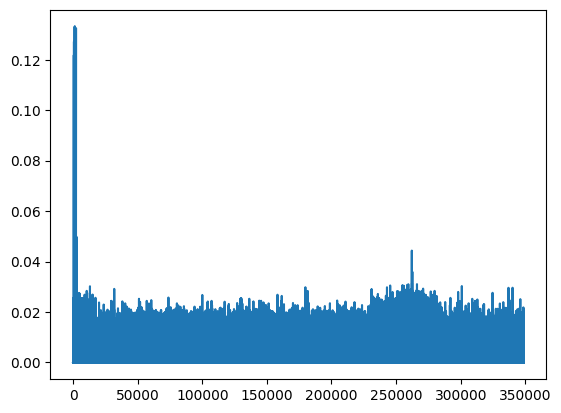

In [13]:
df['IPI'].plot()

### Remove outliers (e.g., 1st and 9th percentile)

<Axes: >

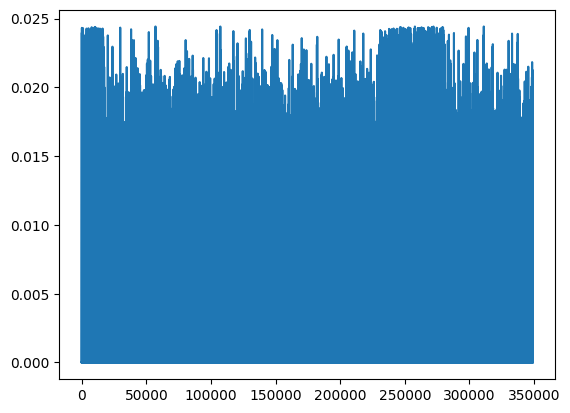

In [14]:
# Function to remove outliers
def remove_outliers(df, columns):
    for col in columns:
        lower_bound = np.percentile(df[col], 0.1)  # 1st percentile
        upper_bound = np.percentile(df[col], 99.9)  # 99th percentile
        df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]  # Filter rows within bounds
    return df

columns_to_check = ['IPI']  # Columns to apply outlier removal
df = remove_outliers(df, columns=columns_to_check)
df['IPI'].plot()

<Axes: >

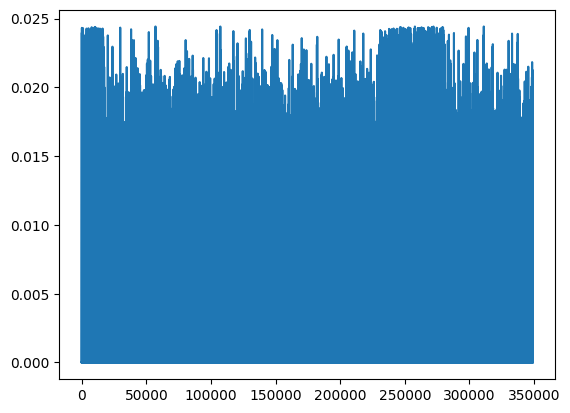

In [15]:
df['IPI'].plot()

### Copy and save remaining packets that will be further used to fill the `window_packets` in the **replacement** script

In [16]:
from sklearn.preprocessing import MinMaxScaler

# Step 1: Save rows from index N+1 onwards into another DataFrame
df_remaining = df.loc[N:, ['IPI']]

print("df_remaining:", df_remaining.head())

# Step 2: Initialize the MinMaxScaler with feature range [-1, 1]
scaler_remaining = MinMaxScaler(feature_range=(-1, 1))

# Step 3: Fit the scaler and transform the data
# Assuming all columns except the index are numeric
scaled_data_remaining = scaler_remaining.fit_transform(df_remaining)

#print("Scaled prediction range:", predictions.min(), predictions.max())
print("Scaler data range:", scaler_remaining.data_min_, scaler_remaining.data_max_)

# Step 4: Create a new DataFrame with the scaled data
df_remaining_scaled = pd.DataFrame(scaled_data_remaining, columns=df_remaining.columns, index=df_remaining.index)

print("df_remaining_scaled:", df_remaining_scaled.head())

# Step 5: Export the scaled DataFrame to a CSV file
df_remaining_scaled.to_csv("packets_N_to_end_scaled_DL.csv", index=False)

# Step 6: Save the scaler_remaining using joblib
joblib.dump(scaler_remaining, "minmax_scaler_remaining_DL.joblib")


df_remaining:                 IPI
10000  1.100000e-08
10001  1.400000e-08
10002  1.100000e-08
10003  1.200000e-08
10004  1.100000e-08
Scaler data range: [1.1e-08] [0.02442985]
df_remaining_scaled:        IPI
10000 -1.0
10001 -1.0
10002 -1.0
10003 -1.0
10004 -1.0


['minmax_scaler_remaining_DL.joblib']

In [17]:
#print("Scaled prediction range:", predictions.min(), predictions.max())
print("Scaler data range:", scaler_remaining.data_min_, scaler_remaining.data_max_)

Scaler data range: [1.1e-08] [0.02442985]


<Axes: >

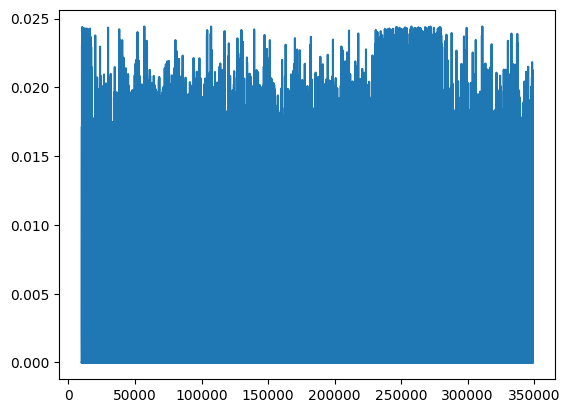

In [18]:
df_remaining['IPI'].plot()

### Get ONLY the first N packets 

In [19]:
df = df.iloc[:N]
df

,IPI
1,6.900000e-08
2,2.100000e-08
3,1.300000e-08
4,1.400000e-08
5,1.300000e-08
...,...
10089,1.715738e-02
10090,7.600000e-08
10091,2.300000e-08
10092,2.300000e-08


In [20]:
# Create lagged features 
# Lagging the IPI_display difference values
# df['lag_1_IPI'] = df['IPI'].shift(1)
# df['lag_2_IPI'] = df['IPI'].shift(2)
# df['lag_3_IPI'] = df['IPI'].shift(3)

# # Rolling window calculations
# df['rolling_mean_IPI'] = df['IPI'].rolling(window=WINDOW_SIZE).mean()
# df['rolling_std_IPI'] = df['IPI'].rolling(window=WINDOW_SIZE).std()
# df['rolling_sum_IPI'] = df['IPI'].rolling(window=WINDOW_SIZE).sum()

# # Lagging the ipv4_ts difference values
# df['lag_1_Length'] = df['Length'].shift(1)
# df['lag_2_Length'] = df['Length'].shift(2)
# df['lag_3_Length'] = df['Length'].shift(3)

# # Rolling window calculations
# df['rolling_mean_Length'] = df['Length'].rolling(window=WINDOW_SIZE).mean()
# df['rolling_std_Length'] = df['Length'].rolling(window=WINDOW_SIZE).std()
# df['rolling_sum_Length'] = df['Length'].rolling(window=WINDOW_SIZE).sum()

# Drop NaN values because of the shift operations
#df = df.dropna()

# selected_manual = ['IPI_display', 'Length', 'stream_id', 'lag_1_IPI_display', 'lag_2_IPI_display', 'lag_3_IPI_display',
#                    'rolling_mean_IPI_display', 'rolling_std_IPI_display', 'lag_1_Length', 'lag_2_Length', 'lag_3_Length',
#                    'rolling_mean_Length', 'rolling_std_Length', 'rolling_sum_Length']

#selected_manual = ['IPI', 'Length', 'stream_id', 'lag_1_IPI', 'lag_2_IPI', 'lag_3_IPI',
#                   'lag_1_Length', 'lag_2_Length', 'lag_3_Length']

#selected_manual = ['IPI', 'Length', 'stream_id']

# selected_manual = ['IPI', 'Length']

# df = df[selected_manual]
# df

In [21]:
#df[['IPI']].plot(subplots=True, layout=(1, 2), figsize=(12, 4), title=['IPI'])

### Split data

In [22]:
def create_complete_windows(group, window_size, target=[], ignored_features=[]):
    """Helper function to create complete windows from a group, excluding specified features from sequences."""
    sequences, targets = [], []
    num_windows = (len(group) - window_size) // window_size  # Count of complete windows

    # Determine feature columns to use for input sequences
    feature_columns = group.columns.difference(ignored_features)

    if num_windows > 0:
        for i in range(num_windows):
            start_idx = i * window_size
            end_idx = start_idx + window_size

            # Append the features (excluding target and ignored features) to sequences
            sequences.append(group.iloc[start_idx:end_idx][feature_columns].to_numpy())

            # Append the target value at 'end_idx' to the targets list
            targets.append(group.iloc[end_idx][target].to_numpy() if len(target) > 1 else group.iloc[end_idx][target])
    
    return sequences, targets

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import joblib

# Assuming 'df' is your DataFrame
window_size = WINDOW_SIZE
target_columns = ['IPI']  # Specify target columns
ignored_features = []  # Specify ignored features

# Delete 'Class' column because there will be a single class in this case
if 'Class' in df.columns:
    df = df.drop('Class', axis=1)

for col in ignored_features:
    if col in df.columns:
        df = df.drop(col, axis=1)

# First, split into train+test and test sets
train_df, test_df = train_test_split(df, test_size=0.2, shuffle=False, random_state=42)

# Apply MinMaxScaler to each split
scaler = MinMaxScaler(feature_range=(-1, 1))

# Scale and convert back to DataFrame
train_df = pd.DataFrame(scaler.fit_transform(train_df), columns=df.columns)
test_df = pd.DataFrame(scaler.transform(test_df), columns=df.columns)

# Save the MinMaxScaler
joblib.dump(scaler, 'minmax_scaler_DL.joblib')
print("Saved MinMaxScaler to 'minmax_scaler_DL.joblib'.")

# Print scaler parameters
print("Scaler min_ shape:", scaler.min_.shape)
print("Scaler scale_ shape:", scaler.scale_.shape)


# (Testing) 
test_scaler = joblib.load('minmax_scaler_DL.joblib')

# (Testing)
print("(Testing) Scaler min_ shape:", scaler.min_.shape)
print("(Testing) Scaler scale_ shape:", scaler.scale_.shape)


# --- Carve a validation set from the (already scaled) training portion ---
# The 80/20 train/test split above and the scaler (fit on the 80% train) are
# left unchanged, so the test set and any previously reported test metrics
# stay identical. The validation set is taken from the temporal tail of the
# train portion (shuffle=False) and is used only to monitor validation loss
# and to drive early stopping.
TEST_SPLIT = 0.2  # must match test_size above (kept fixed for the paper results)
val_relative = VAL_SPLIT / (1.0 - TEST_SPLIT)  # fraction of the train portion -> val
train_df, val_df = train_test_split(train_df, test_size=val_relative,
                                    shuffle=False, random_state=42)
print(f"Global split -> train: {len(train_df)} | val: {len(val_df)} | test: {len(test_df)} rows")

# Create windows for training, validation, and testing splits
X_train, y_train = create_complete_windows(train_df, window_size, target=target_columns, ignored_features=ignored_features)
X_val, y_val = create_complete_windows(val_df, window_size, target=target_columns, ignored_features=ignored_features)
X_test, y_test = create_complete_windows(test_df, window_size, target=target_columns, ignored_features=ignored_features)

# Convert lists to numpy arrays for easier handling with machine learning models
X_train = np.array(X_train)
y_train = np.array(y_train)
X_val = np.array(X_val)
y_val = np.array(y_val)
X_test = np.array(X_test)
y_test = np.array(y_test)

# Print shapes for verification
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

### Save dataset split

In [24]:
# Save numpy arrays to a compressed .npz file
np.savez_compressed('train_test_splits_DL.npz', 
                    X_train=X_train, y_train=y_train, 
                    X_test=X_test, y_test=y_test)

print("Data saved to 'train_test_splits_DL.npz'.")

Data saved to 'train_test_splits_DL.npz'.


### Load data from npz

In [25]:
# # Load the .npz file
# data = np.load('train_test_splits.npz')

# # Access the arrays
# X_train = data['X_train']
# y_train = data['y_train']
# X_test = data['X_test']
# y_test = data['y_test']

# print("Data loaded successfully.")
# print("X_train shape:", X_train.shape)
# print("y_train shape:", y_train.shape)
# print("X_test shape:", X_test.shape)
# print("y_test shape:", y_test.shape)

### Number of data points after data split

In [26]:
# total rows before split
print(f"Total rows before split:                       {df.shape[0]}")
# total rows after split
print(f"Total rows across all splits (train/val/test): {X_train.shape[0] * X_train.shape[1] + X_test.shape[0] * X_test.shape[1]}")

Total rows before split:                       10000
Total rows across all splits (train/val/test): 9980


In [ ]:
# Model definition `create_model10_temp` has been moved to src.flowsync.models.architectures
# and renamed to `create_complex_gru_model`
from src.flowsync.models.architectures import create_complex_gru_model

### Force tensorflow to use float64

In [28]:
# # Set the global default data type to float64
#tf.keras.backend.set_floatx('float64')

### Log-Cosh loss - This is a smoother version of the Huber loss that is less sensitive to outliers but still provides gradient information even for small errors

In [29]:
def log_cosh_loss(y_true, y_pred):
    return tf.reduce_mean(tf.math.log(tf.cosh(y_pred - y_true)))

### Epsilon-Insensitive Loss

In [30]:
def epsilon_insensitive_loss(epsilon=0.1):
    """
    Epsilon-insensitive loss function.

    Arguments:
    epsilon -- the threshold below which errors are not penalized (default: 0.1)

    Returns:
    A function that calculates epsilon-insensitive loss.
    """
    def loss(y_true, y_pred):
        error = K.abs(y_true - y_pred)  # Calculate the absolute error
        return K.mean(K.maximum(0.0, error - epsilon))  # Penalize only errors greater than epsilon
    
    return loss

### Mish activation function

In [ ]:
# mish activation is imported from src.flowsync.models.architectures

In [ ]:
import os
from src.flowsync.utils.training_diagnostics import (
    make_training_callbacks, report_early_stopping_epoch,
)

# Direction for this notebook ('DL' = downlink, 'UL' = uplink). The game label
# is derived from the loaded data file so figures/checkpoints adapt per run.
DIRECTION = 'DL'
game_label = os.path.splitext(os.path.basename(file_path))[0]  # e.g. 'DS_Kombat_DL_only'

model10 = create_complex_gru_model(
    output_size=1,
    window_size=X_train.shape[1],
    num_features=X_train.shape[2],
    num_rnn_neurons=[128, 128],
    print_summary=True,
    dropout_rnn=0.2,
    dropout_window=0.2,
    loss_func=['mae'],
    activation_rnn=mish,  # Sigmoid for hidden layers (if you want 0-1 output)
    activation_conv='tanh',  # Conv layers with ReLU
    activation_out='tanh',  # Sigmoid for output layers to keep the output between 0-1
    learning_rate=0.0001,  # if I increase (e.g., 0.01) I might have more noise
    use_layer_norm=True,
    num_attention_heads=8,  # number of attention mechanism heads. ZERO if None
    l1_reg=0.001,
    l2_reg=0.001,
    conv_kernels=[3, 5, 7],
    filter_sizes=[128, 128, 128],
    optimizer='Adam',
    num_dense_neurons=[],
    use_lstm=False,
    use_attention=False,
    activation_dense='tanh',  # Sigmoid for dense layers as well
    stateful=False,
)

# Standard callbacks driven by the hyperparameters above: early stopping with
# restore_best_weights, LR reduction on plateau, and best-checkpoint saving.
# The checkpoint filename matches the one the save/assert cells below reload.
callbacks, es10, cp10 = make_training_callbacks(
    checkpoint_path=f'model10_{DIRECTION}.keras',
    monitor='val_loss',
    patience_early_stopping=PATIENCE_EARLY_STOPPING,
    patience_reduce_lr=PATIENCE_REDUCE_LR,
    factor_reduction=FACTOR_REDUCTION,
)

# Train with an explicit validation set so val_loss is recorded each epoch.
history10 = model10.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=callbacks,
)

# Report the epoch selected by early stopping (best val_loss).
best_epoch = report_early_stopping_epoch(history10, early_stopping=es10)

# Plot training vs validation loss across epochs, mark the selected epoch, and
# save the figure (PDF for the paper + PNG) under notebooks/prediction/figures/.
fig_path = f'notebooks/prediction/figures/loss_curve_{game_label}.pdf'
plot_train_and_val_loss(
    history10,
    best_epoch=best_epoch,
    save_path=fig_path,
    title=f'Training vs Validation Loss ({game_label})',
)

7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 222ms/step
Predictions shape: (199, 1)
Ground truth shape: (199, 1)


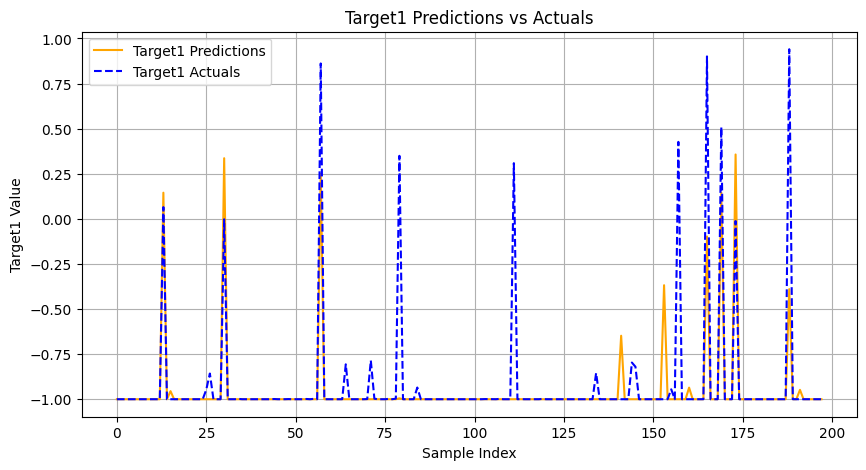

In [33]:
results_df = plot_predictions_generic(model10, X_test, y_test, start=0, end=int(y_test.shape[0]-1), #step=10)
                                        step=int((y_test.shape[0]-1)/100))

In [34]:
predictions = model10.predict(X_test)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


In [35]:
predictions.shape

(199, 1)

### Save model10 predictions

In [36]:
# Save numpy arrays to a compressed .npz file
np.savez_compressed('model10_predictions_DL.npz', model10_predictions=predictions)

### Save and Assert Model

In [37]:
import numpy as np
from keras.models import load_model

# Predict Using Original Model
original_predictions = model10.predict(X_test)

# Save model: if cp10.best is not inf
if np.isinf(cp10.best):
    print("Model saved successfully.")
    model10.save('model10_DL.keras')
else:
    print("Model not saved. Best metric is in callback (cp) - e.g., validation, training, or test loss")

# Save and load model (add custom_objects if needed)
loaded_model = load_model('model10_DL.keras')
loaded_predictions = loaded_model.predict(X_test)

# Compare predictions
diff = np.abs(original_predictions - loaded_predictions)
print("Max difference:", np.max(diff))
print("Mean difference:", np.mean(diff))

# Use a relaxed tolerance
assert np.allclose(original_predictions, loaded_predictions, rtol=1e-5, atol=1e-7), "Mismatch in predictions!"

print("Model verification successful! Predictions are consistent.")

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Model saved successfully.
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 149ms/step
Max difference: 4.6938658e-07
Mean difference: 2.3100544e-08
Model verification successful! Predictions are consistent.


In [38]:
# from keras.utils import plot_model
# from keras.models import load_model
# import sys
# sys.path.append("../../helper_funcs")
# from custom_models import *

# # Step 4: Load the Saved Model
# loaded_model = load_model('model10.keras')
# print("Model loaded successfully from 'model10.keras'.")

# print("Model verification successful! Predictions are consistent.")

# # Assuming 'model' is your Keras model
# plot_model(
# loaded_model,
# to_file="model.png",
# show_shapes=True,
# show_layer_names=True,
# rankdir="TB",
# expand_nested=False,
# show_layer_activations=False,
# dpi=70,
# )